## Burlington Vermont Policing Data EDA

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("C:/Users/USER/OneDrive/Desktop/Practice Projects/BurlingtonVermont_EDA Project/data/vt_burlington_2023_01_26.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36845 entries, 0 to 36844
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   raw_row_number              36845 non-null  str    
 1   date                        36842 non-null  str    
 2   time                        36842 non-null  str    
 3   location                    36842 non-null  str    
 4   lat                         31103 non-null  float64
 5   lng                         31103 non-null  float64
 6   subject_age                 30888 non-null  float64
 7   subject_race                35140 non-null  str    
 8   subject_sex                 35528 non-null  str    
 9   department_name             36845 non-null  str    
 10  type                        36845 non-null  str    
 11  violation                   36377 non-null  str    
 12  arrest_made                 36115 non-null  object 
 13  citation_issued             36115 non-null

C:\Users\USER\AppData\Local\Temp\ipykernel_16644\3516254218.py:1: DtypeWarning: Columns (0: reason_for_stop, 1: vehicle_registration_state) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("C:/Users/USER/OneDrive/Desktop/Practice Projects/BurlingtonVermont_EDA Project/data/vt_burlington_2023_01_26.csv")


In [4]:
for i in df.columns:
    print(f"{i}: {df.count()[i]}")

raw_row_number: 36845
date: 36842
time: 36842
location: 36842
lat: 31103
lng: 31103
subject_age: 30888
subject_race: 35140
subject_sex: 35528
department_name: 36845
type: 36845
violation: 36377
arrest_made: 36115
citation_issued: 36115
warning_issued: 36115
outcome: 36097
contraband_found: 432
search_conducted: 36845
search_basis: 432
reason_for_search: 432
reason_for_stop: 31092
vehicle_registration_state: 5508
raw_race: 35181
raw_gender: 35551
raw_contraband_evidence: 35939
raw_outcome_of_stop: 36115


# Among stopped drivers, does the probability of being searched differ by race

Search rate = Searches/Stops

In [5]:
df["date"] = pd.to_datetime(df["date"], errors="coerce") # Convert the "date" column to datetime, coercing errors
df["year"] = df["date"].dt.year # Extract the year from the "date" column
df["hour"] = pd.to_datetime(df["time"], format="%H:%M:%S", errors="coerce").dt.hour # Extract the hour from the "time" column
df["night"] = ((df["hour"] >= 20) | (df["hour"] < 6)).astype(int) # Create a "night" column indicating if the time is between 8 PM and 6 AM
df["searched"] = df["search_conducted"].astype(int) # Convert the "search_conducted" column to integer

In [6]:
d = df.dropna(subset=["subject_race"]) # Drop rows where "subject_race" is NaN
tab = df.groupby("subject_race")["searched"].agg(stops="count", searches="sum") # Group by "subject_race" and calculate the number of stops and searches for each race category
tab["rate"] = (tab["searches"] / tab["stops"]) * 100 # Calculate the search rate for each race category
print(tab.round(2)) # Print the table showing the number of stops, searches, and search rate for each race category

                        stops  searches  rate
subject_race                                 
asian/pacific islander   1453         9  0.62
black                    2935       100  3.41
hispanic                  223         5  2.24
other                     472         5  1.06
unknown                    63         0  0.00
white                   29994       300  1.00


# Which areas have the highest police activity?

In [7]:
loc = df["location"].dropna().str.strip().str.lower()
loc = loc.str.replace(", burlington, vt.*", "", regex=True)   # drop city/state/zip
loc = loc.str.replace(" / ", " at ", regex=False)             # unify the separator
df["loc_clean"] = loc
print(df["loc_clean"])

0                  maple st at pine st
1                  north ave at rt 127
2                        153 church st
3                bank st at st paul st
4                 oak st at st mary st
                     ...              
36840    manhattan dr at lafountain st
36841       n prospect st/north street
36842           n prospect st/north st
36843           manhattan dr/spring st
36844                 north st/rose st
Name: loc_clean, Length: 36845, dtype: str


In [8]:
highest_activity_loc = df["loc_clean"].value_counts()
print(highest_activity_loc.head(10))
print("Top 10 share:", round(highest_activity_loc.head(10).sum() / highest_activity_loc.sum() * 100, 1), "%")
print("Top 50 share:", round(highest_activity_loc.head(50).sum() / highest_activity_loc.sum() * 100, 1), "%")


loc_clean
north ave at institute rd         555
main st at s union st             356
battery st at cherry st           354
riverside ave at n prospect st    342
main st at s willard st           314
riverside ave at hillside ter     313
main st at s winooski ave         312
main st at s prospect st          310
battery st at college st          293
north ave at north st             286
Name: count, dtype: int64
Top 10 share: 9.3 %
Top 50 share: 28.7 %


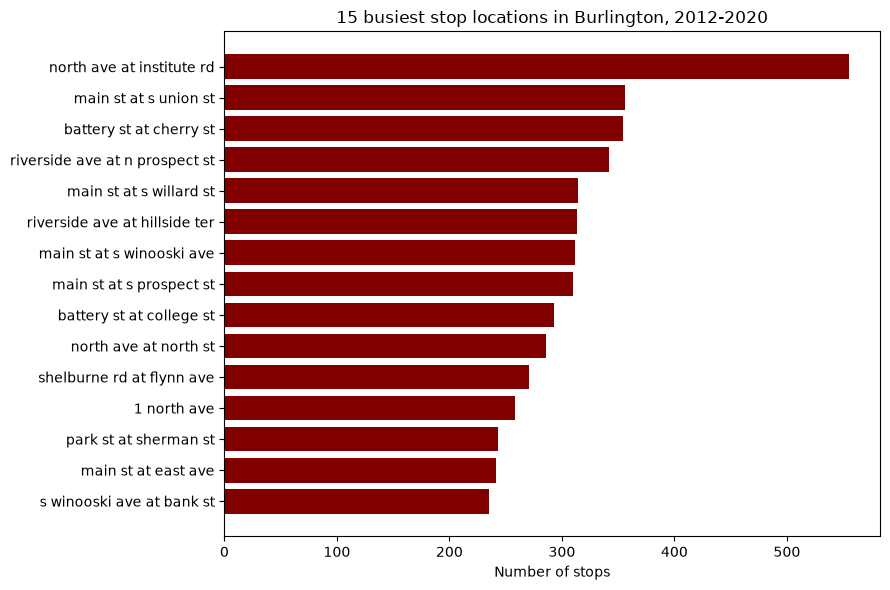

In [9]:
# Bar chart of the busiest locations
top15 = highest_activity_loc.head(15).sort_values()   # sort so the busiest ends up at the top

plt.figure(figsize=(9, 6))
plt.barh(top15.index, top15.values, color="maroon")
plt.xlabel("Number of stops")
plt.title("15 busiest stop locations in Burlington, 2012-2020")
plt.tight_layout() 
plt.show()

# After a police stop in Burlington, is the outcome (warning, citation or arrest) different for people of different races?


Race: Black vs. white drivers (the two groups with enough stops to compare reliably).
Other groups are shown with counts but not tested.

In [33]:
clean = df.dropna(subset=["subject_race"]).copy() # Drop rows where "subject_race" is NaN
print("Rows dropped for missing race:", len(df) - len(clean))

counts = pd.crosstab(clean["subject_race"], clean["outcome"], margins=True) # Number of stops for each race and outcome
print("Number of cases by race and outcome:")
print(counts)

pct = pd.crosstab(clean["subject_race"], clean["outcome"], normalize="index") * 100 # Row percentages, so each race adds up to 100
print("Percentage of cases by race and outcome:")
print(pct.round(1))

Rows dropped for missing race: 1190
Number of cases by race and outcome:
outcome                 arrest  citation  warning    All
subject_race                                            
asian/pacific islander      12       371     1061   1444
black                       41       975     1896   2912
hispanic                     2        74      146    222
other                        4       164      293    461
unknown                      0         7       56     63
white                      305      7861    21639  29805
All                        364      9452    25091  34907
Percentage of cases by race and outcome:
outcome                 arrest  citation  warning
subject_race                                     
asian/pacific islander     0.8      25.7     73.5
black                      1.4      33.5     65.1
hispanic                   0.9      33.3     65.8
other                      0.9      35.6     63.6
unknown                    0.0      11.1     88.9
white                  

Black vs White Drivers

In [34]:
bw = d[d["subject_race"].isin(["black", "white"])].copy() # Keep only black and white drivers

rates = pd.crosstab(bw["subject_race"], bw["outcome"], normalize="index") * 100 # Percentage of stops ending in each outcome
print(rates.round(1))

gap = rates.loc["black"] - rates.loc["white"] # Difference in percentage points
ratio = rates.loc["black"] / rates.loc["white"] # How many times higher the black rate is
print("\nGap (black minus white, percentage points):")
print(gap.round(1))
print("\nBlack rate divided by white rate:")
print(ratio.round(2))

outcome       arrest  citation  warning
subject_race                           
black            1.4      33.5     65.1
white            1.0      26.4     72.6

Gap (black minus white, percentage points):
outcome
arrest      0.4
citation    7.1
warning    -7.5
dtype: float64

Black rate divided by white rate:
outcome
arrest      1.38
citation    1.27
warning     0.90
dtype: float64


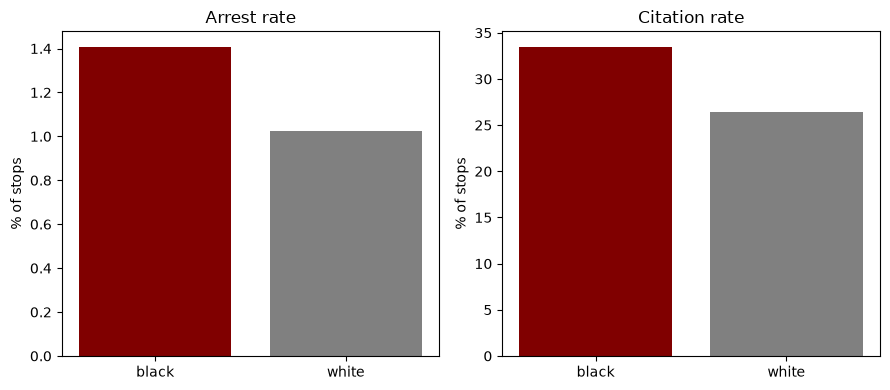

In [35]:
# Arrest and citation rates, black vs. white
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, o in zip(axes, ["arrest", "citation"]):
    ax.bar(rates.index, rates[o], color=["maroon", "gray"])
    ax.set_title(f"{o.capitalize()} rate")
    ax.set_ylabel("% of stops")
plt.tight_layout()
plt.show()